# Numerical Optimization — Theory Notebook

> *"In theory there is no difference between theory and practice. In practice there is."*

Interactive derivations: line search, Newton's method, L-BFGS, trust region, finite differences, Adam as diagonal quasi-Newton.

**Companion:** [notes.md](notes.md) | [exercises.ipynb](exercises.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


In [2]:
import numpy as np
import scipy.optimize as sopt
import numpy.linalg as nla

try:
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    try:
        import seaborn as sns
        sns.set_theme(style='whitegrid', palette='colorblind')
        HAS_SNS = True
    except ImportError:
        plt.style.use('seaborn-v0_8-whitegrid')
        HAS_SNS = False
    mpl.rcParams.update({
        'figure.figsize': (10, 6), 'figure.dpi': 120,
        'font.size': 13, 'axes.titlesize': 15,
        'axes.spines.top': False, 'axes.spines.right': False,
    })
    HAS_MPL = True
except ImportError:
    HAS_MPL = False

COLORS = {
    'primary':   '#0077BB',
    'secondary': '#EE7733',
    'tertiary':  '#009988',
    'error':     '#CC3311',
    'neutral':   '#555555',
}

np.set_printoptions(precision=8, suppress=True)
np.random.seed(42)
print('Setup complete.')

print("Chapter helper setup complete.")

Setup complete.
Chapter helper setup complete.


---

## 1. Test Functions

Standard optimization test functions used throughout this notebook.

In [3]:
# === 1.1 Test Functions ===

def rosenbrock(x):
    return 100 * (x[1] - x[0]**2)**2 + (1 - x[0])**2

def rosenbrock_grad(x):
    g = np.zeros(2)
    g[0] = -400 * x[0] * (x[1] - x[0]**2) - 2 * (1 - x[0])
    g[1] = 200 * (x[1] - x[0]**2)
    return g

def rosenbrock_hess(x):
    H = np.zeros((2, 2))
    H[0, 0] = -400 * (x[1] - x[0]**2) + 800 * x[0]**2 + 2
    H[0, 1] = -400 * x[0]
    H[1, 0] = -400 * x[0]
    H[1, 1] = 200
    return H

def quad(H_diag):
    """Quadratic f(x) = 0.5 x^T diag(H_diag) x."""
    def f(x): return 0.5 * np.sum(H_diag * x**2)
    def g(x): return H_diag * x
    def h(x): return np.diag(H_diag)
    return f, g, h

# Verify at minimum
x_star = np.array([1.0, 1.0])
print(f'Rosenbrock at minimum (1,1): {rosenbrock(x_star)}')
print(f'Gradient at minimum: {rosenbrock_grad(x_star)}')
H_star = rosenbrock_hess(x_star)
kappa = nla.cond(H_star)
print(f'kappa(H*) = {kappa:.2f}')

Rosenbrock at minimum (1,1): 0.0
Gradient at minimum: [-0.  0.]
kappa(H*) = 2508.01


---

## 2. Line Search Methods

Implement and compare Armijo backtracking and Wolfe conditions.

In [4]:
# === 2.1 Backtracking Armijo ===

def armijo_search(f, g, x, p, alpha0=1.0, rho=0.5, c1=1e-4, max_iter=50):
    """Backtracking line search with Armijo (sufficient decrease) condition."""
    alpha = alpha0
    f0 = f(x)
    slope = g(x) @ p
    assert slope < 0, 'p must be a descent direction'

    for i in range(max_iter):
        if f(x + alpha * p) <= f0 + c1 * alpha * slope:
            break
        alpha *= rho

    return alpha, i + 1

# Test: gradient descent on Rosenbrock
x = np.array([-1.0, 0.5])
g = rosenbrock_grad(x)
p = -g  # Steepest descent direction

alpha_arm, n_evals = armijo_search(rosenbrock, rosenbrock_grad, x, p)
x_new = x + alpha_arm * p

print(f'Armijo step size: {alpha_arm:.6f} ({n_evals} evaluations)')
print(f'f(x) = {rosenbrock(x):.6f}')
print(f'f(x + alpha*p) = {rosenbrock(x_new):.6f}')
print(f'Sufficient decrease satisfied: {rosenbrock(x_new) <= rosenbrock(x) + 1e-4 * alpha_arm * (g @ p)}')

Armijo step size: 0.001953 (10 evaluations)
f(x) = 29.000000
f(x + alpha*p) = 13.682896
Sufficient decrease satisfied: True


In [5]:
# === 2.2 Gradient Descent with Armijo Line Search ===

def gradient_descent_ls(f, grad_f, x0, tol=1e-8, max_iter=10000):
    """GD with Armijo backtracking."""
    x = x0.copy()
    history = [x.copy()]
    losses = [f(x)]

    for k in range(max_iter):
        g = grad_f(x)
        if nla.norm(g) < tol:
            break
        p = -g
        alpha, _ = armijo_search(f, grad_f, x, p)
        x = x + alpha * p
        history.append(x.copy())
        losses.append(f(x))

    return x, history, losses

x0 = np.array([-1.0, 0.5])
x_gd, hist_gd, loss_gd = gradient_descent_ls(rosenbrock, rosenbrock_grad, x0, tol=1e-6)
print(f'GD with Armijo: {len(loss_gd)} iterations')
print(f'Solution: {x_gd}')
print(f'Final loss: {loss_gd[-1]:.2e}')

GD with Armijo: 10001 iterations
Solution: [1.00000517 1.00001033]
Final loss: 2.67e-11


---

## 3. Newton's Method

Newton's method achieves quadratic convergence near a non-degenerate minimum.

In [6]:
# === 3.1 Newton's Method with Line Search ===

def newton_ls(f, grad_f, hess_f, x0, tol=1e-10, max_iter=200):
    """Newton's method with Armijo backtracking."""
    x = x0.copy()
    history = [x.copy()]
    losses = [f(x)]

    for k in range(max_iter):
        g = grad_f(x)
        if nla.norm(g) < tol:
            break

        H = hess_f(x)
        # Modified Cholesky: add tau*I if H is not positive definite
        try:
            L = nla.cholesky(H)
            p = -nla.solve(H, g)  # Newton direction
        except nla.LinAlgError:
            p = -g  # Fall back to gradient descent if H is indefinite

        # Ensure descent direction
        if grad_f(x) @ p >= 0:
            p = -g

        alpha, _ = armijo_search(f, grad_f, x, p)
        x = x + alpha * p
        history.append(x.copy())
        losses.append(f(x))

    return x, history, losses

x0 = np.array([-1.0, 0.5])
x_nt, hist_nt, loss_nt = newton_ls(rosenbrock, rosenbrock_grad, rosenbrock_hess, x0, tol=1e-10)
print(f'Newton: {len(loss_nt)} iterations')
print(f'Solution: {x_nt}')
print(f'Final loss: {loss_nt[-1]:.2e}')

ok = nla.norm(x_nt - [1.0, 1.0]) < 1e-6
print(f"{'PASS' if ok else 'FAIL'} - Newton converged to correct minimum")

Newton: 21 iterations
Solution: [1. 1.]
Final loss: 1.24e-30
PASS - Newton converged to correct minimum


In [7]:
# === 3.2 Quadratic Convergence Demonstration ===

# On a quadratic, Newton converges in ONE step
H_diag = np.array([2.0, 10.0, 50.0, 100.0])
kappa = H_diag.max() / H_diag.min()
f_quad, g_quad, h_quad = quad(H_diag)

x0 = np.ones(4)

# Newton step
x_newt = x0 - nla.solve(h_quad(x0), g_quad(x0))
print(f'Newton on quadratic: one step result = {x_newt}')
print(f'(Should be [0,0,0,0])')
print(f'Loss after one Newton step: {f_quad(x_newt):.2e}')

# GD convergence on same problem
eta_opt = 2 / (H_diag.max() + H_diag.min())
rate_gd = (kappa - 1) / (kappa + 1)
print(f'\nGD convergence rate: {rate_gd:.4f}')
print(f'GD steps to 1e-8: ~{int(-8 / np.log10(rate_gd)) + 1}')
print(f'Newton steps: 1 (exact for quadratic!)')

Newton on quadratic: one step result = [0. 0. 0. 0.]
(Should be [0,0,0,0])
Loss after one Newton step: 0.00e+00

GD convergence rate: 0.9608
GD steps to 1e-8: ~461
Newton steps: 1 (exact for quadratic!)


---

## 4. L-BFGS: Limited Memory BFGS

Implement the two-loop recursion and demonstrate super-linear convergence.

In [8]:
# === 4.1 L-BFGS Two-Loop Recursion ===

def lbfgs_direction(g, s_list, y_list):
    """Compute L-BFGS search direction via two-loop recursion."""
    m = len(s_list)

    if m == 0:
        return -g  # Initial step: steepest descent

    rho = [1.0 / (y @ s) for s, y in zip(s_list, y_list)]
    q = g.copy()
    alpha = np.zeros(m)

    # First loop (backward)
    for i in range(m - 1, -1, -1):
        alpha[i] = rho[i] * (s_list[i] @ q)
        q -= alpha[i] * y_list[i]

    # Scale by initial Hessian (Barzilai-Borwein)
    s_last, y_last = s_list[-1], y_list[-1]
    gamma = (s_last @ y_last) / (y_last @ y_last)
    r = gamma * q

    # Second loop (forward)
    for i in range(m):
        beta = rho[i] * (y_list[i] @ r)
        r += s_list[i] * (alpha[i] - beta)

    return -r

# Full L-BFGS optimizer
def lbfgs(f, grad_f, x0, m=10, tol=1e-10, max_iter=500):
    x = x0.copy()
    s_list, y_list = [], []
    losses = [f(x)]
    g = grad_f(x)

    for k in range(max_iter):
        if nla.norm(g) < tol:
            break

        p = lbfgs_direction(g, s_list, y_list)

        # Line search
        alpha, _ = armijo_search(f, grad_f, x, p, alpha0=1.0)

        x_new = x + alpha * p
        g_new = grad_f(x_new)

        s = x_new - x
        y = g_new - g
        if y @ s > 1e-10:  # Only update if secant condition holds
            s_list.append(s)
            y_list.append(y)
            if len(s_list) > m:
                s_list.pop(0)
                y_list.pop(0)

        x, g = x_new, g_new
        losses.append(f(x))

    return x, losses

x0 = np.array([-1.0, 0.5])
x_lb, loss_lb = lbfgs(rosenbrock, rosenbrock_grad, x0, m=10, tol=1e-10)
print(f'L-BFGS: {len(loss_lb)} iterations')
print(f'Solution: {x_lb}')
print(f'Final loss: {loss_lb[-1]:.2e}')

ok = nla.norm(x_lb - [1.0, 1.0]) < 1e-5
print(f"{'PASS' if ok else 'FAIL'} - L-BFGS converged")

L-BFGS: 42 iterations
Solution: [1. 1.]
Final loss: 3.78e-25
PASS - L-BFGS converged


---

## 5. Optimizer Comparison

Compare GD, Newton, and L-BFGS on the Rosenbrock function.

GD iterations:      20000
Newton iterations:     20
L-BFGS iterations:     41
Scipy L-BFGS-B:        33


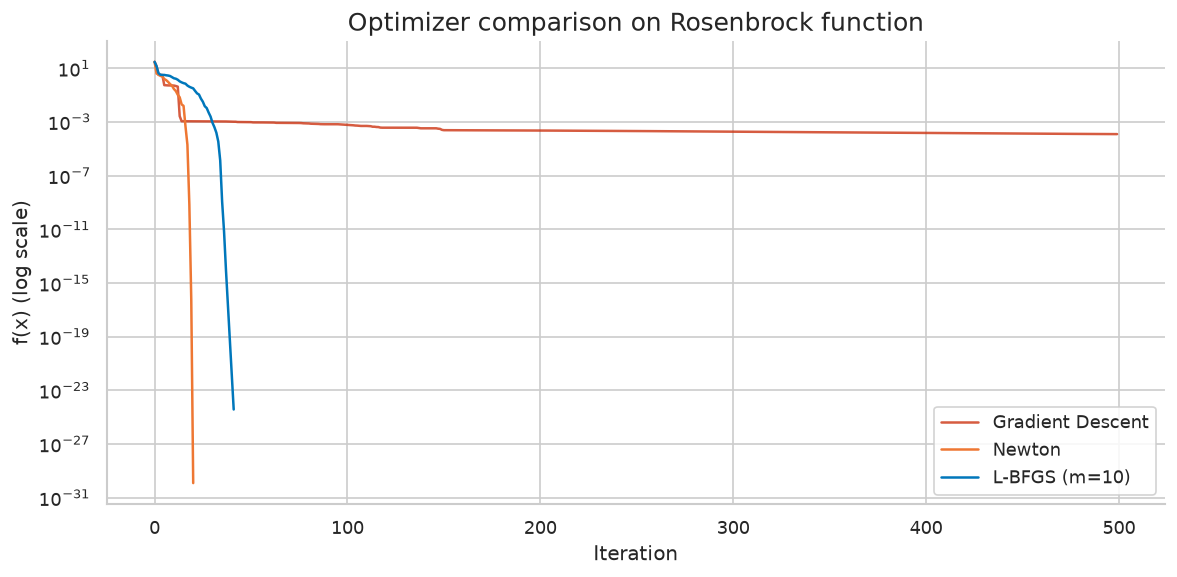

Plot displayed.


In [9]:
# === 5.1 Convergence Comparison ===

x0 = np.array([-1.0, 0.5])

# GD with line search
_, _, loss_gd = gradient_descent_ls(rosenbrock, rosenbrock_grad, x0,
                                     tol=1e-10, max_iter=20000)

# Newton
_, _, loss_nt = newton_ls(rosenbrock, rosenbrock_grad, rosenbrock_hess, x0,
                           tol=1e-10, max_iter=200)

# L-BFGS
_, loss_lb = lbfgs(rosenbrock, rosenbrock_grad, x0, m=10, tol=1e-10, max_iter=500)

# Scipy L-BFGS-B (reference)
res = sopt.minimize(rosenbrock, x0, jac=rosenbrock_grad, method='L-BFGS-B',
                    options={'maxiter': 500, 'ftol': 1e-15, 'gtol': 1e-10})
print(f'GD iterations:     {len(loss_gd)-1:6d}')
print(f'Newton iterations: {len(loss_nt)-1:6d}')
print(f'L-BFGS iterations: {len(loss_lb)-1:6d}')
print(f'Scipy L-BFGS-B:    {res.nit:6d}')

if HAS_MPL:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.semilogy(loss_gd[:500], color=COLORS['error'], label='Gradient Descent', alpha=0.8)
    ax.semilogy(loss_nt, color=COLORS['secondary'], label='Newton')
    ax.semilogy(loss_lb, color=COLORS['primary'], label='L-BFGS (m=10)')
    ax.set_xlabel('Iteration'); ax.set_ylabel('f(x) (log scale)')
    ax.set_title('Optimizer comparison on Rosenbrock function')
    ax.legend()
    plt.tight_layout(); plt.show()
    print('Plot displayed.')

---

## 6. Finite Differences and Gradient Checking

Analyze the accuracy of finite difference approximations and find optimal step sizes.

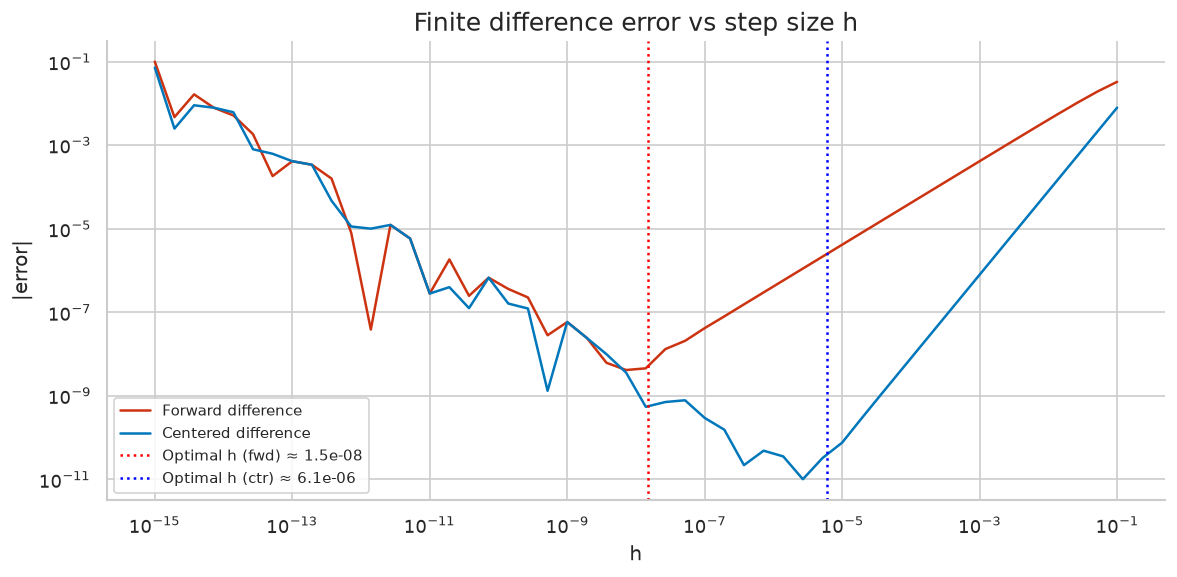

Plot displayed.
Empirical optimal h (forward):  7.20e-09  (theory: 1.49e-08)
Empirical optimal h (centered): 2.68e-06  (theory: 6.06e-06)


In [10]:
# === 6.1 Finite Difference Accuracy vs Step Size ===

def f_test(x): return np.sin(x**2) * np.exp(-x)
def f_grad_true(x): return (2*x*np.cos(x**2) - np.sin(x**2)) * np.exp(-x)

x0 = 1.5
true_grad = f_grad_true(x0)

h_vals = np.logspace(-15, -1, 50)
err_forward  = []
err_centered = []

for h in h_vals:
    g_fwd = (f_test(x0 + h) - f_test(x0)) / h
    g_ctr = (f_test(x0 + h) - f_test(x0 - h)) / (2*h)
    err_forward.append(abs(g_fwd - true_grad))
    err_centered.append(abs(g_ctr - true_grad))

if HAS_MPL:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.loglog(h_vals, err_forward, color=COLORS['error'], label='Forward difference')
    ax.loglog(h_vals, err_centered, color=COLORS['primary'], label='Centered difference')
    h_opt_fwd = np.sqrt(np.finfo(np.float64).eps)
    h_opt_ctr = np.cbrt(np.finfo(np.float64).eps)
    ax.axvline(h_opt_fwd, color='red', linestyle=':', label=f'Optimal h (fwd) ≈ {h_opt_fwd:.1e}')
    ax.axvline(h_opt_ctr, color='blue', linestyle=':', label=f'Optimal h (ctr) ≈ {h_opt_ctr:.1e}')
    ax.set_xlabel('h'); ax.set_ylabel('|error|')
    ax.set_title('Finite difference error vs step size h')
    ax.legend(fontsize=9)
    plt.tight_layout(); plt.show()
    print('Plot displayed.')

# Find empirical optimal
h_opt_fwd_emp = h_vals[np.argmin(err_forward)]
h_opt_ctr_emp = h_vals[np.argmin(err_centered)]
print(f'Empirical optimal h (forward):  {h_opt_fwd_emp:.2e}  (theory: {np.sqrt(np.finfo(np.float64).eps):.2e})')
print(f'Empirical optimal h (centered): {h_opt_ctr_emp:.2e}  (theory: {np.cbrt(np.finfo(np.float64).eps):.2e})')

In [11]:
# === 6.2 Complex-Step Derivative ===

def complex_step_grad(f_complex, x, h=1e-100):
    """Complex-step derivative: Im[f(x + ih)] / h."""
    return np.imag(f_complex(x + 1j * h)) / h

# f must be defined for complex arguments
def f_complex(x): return np.sin(x**2) * np.exp(-x)

x0 = 1.5
true_grad = f_grad_true(x0)
complex_grad = complex_step_grad(f_complex, x0)

print('Complex-step derivative:')
print(f'  True gradient:    {true_grad:.15f}')
print(f'  Complex step:     {complex_grad:.15f}')
print(f'  Error:            {abs(complex_grad - true_grad):.2e}')
print(f'  (centered diff):  {abs((f_test(x0+1e-6) - f_test(x0-1e-6))/(2e-6) - true_grad):.2e}')

ok = abs(complex_grad - true_grad) < 1e-14
print(f"{'PASS' if ok else 'FAIL'} - complex step achieves near machine precision")

Complex-step derivative:
  True gradient:    -0.594105040146235
  Complex step:     -0.594105040146235
  Error:            1.11e-16
  (centered diff):  3.81e-11
PASS - complex step achieves near machine precision


---

## 7. Adam as Diagonal Quasi-Newton

Demonstrate that Adam approximates diagonal preconditioning.

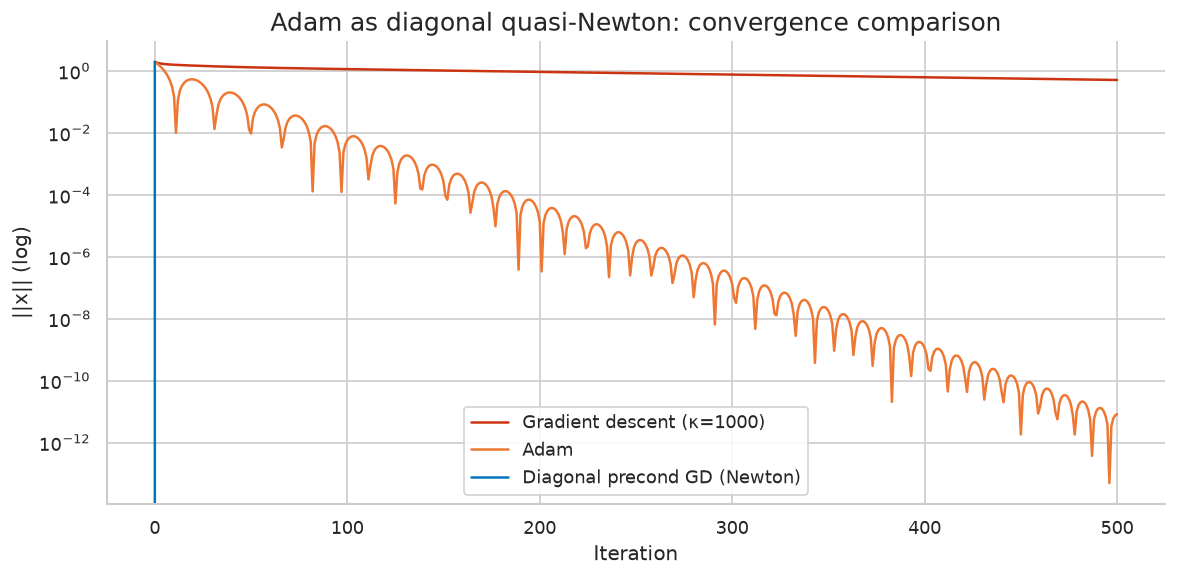

GD final error:     0.5203
Adam final error:   0.0000
Diag precond:       0.0000e+00
PASS - Adam beats GD on ill-conditioned problem


In [12]:
# === 7.1 Convergence on Ill-Conditioned Quadratic ===

h_diag = np.array([1.0, 10.0, 100.0, 1000.0])
kappa = h_diag.max() / h_diag.min()
d = len(h_diag)
x0 = np.ones(d)
n_steps = 500

# === Gradient Descent ===
eta_gd = 2.0 / (h_diag.max() + h_diag.min())
x_gd = x0.copy()
err_gd = [nla.norm(x_gd)]
for _ in range(n_steps):
    g = h_diag * x_gd
    x_gd -= eta_gd * g
    err_gd.append(nla.norm(x_gd))

# === Adam ===
beta1, beta2, eps_a = 0.9, 0.999, 1e-8
alpha_adam = 0.1
x_adam = x0.copy()
m_adam, v_adam = np.zeros(d), np.zeros(d)
err_adam = [nla.norm(x_adam)]
for t in range(1, n_steps + 1):
    g = h_diag * x_adam
    m_adam = beta1 * m_adam + (1 - beta1) * g
    v_adam = beta2 * v_adam + (1 - beta2) * g**2
    m_hat = m_adam / (1 - beta1**t)
    v_hat = v_adam / (1 - beta2**t)
    x_adam -= alpha_adam * m_hat / (np.sqrt(v_hat) + eps_a)
    err_adam.append(nla.norm(x_adam))

# === Diagonal Preconditioned GD (optimal) ===
x_pc = x0.copy()
err_pc = [nla.norm(x_pc)]
for _ in range(n_steps):
    g = h_diag * x_pc
    x_pc -= g / h_diag  # Exact diagonal Newton step
    err_pc.append(nla.norm(x_pc))

if HAS_MPL:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.semilogy(err_gd, color=COLORS['error'], label=f'Gradient descent (κ={int(kappa)})')
    ax.semilogy(err_adam, color=COLORS['secondary'], label='Adam')
    ax.semilogy(err_pc, color=COLORS['primary'], label='Diagonal precond GD (Newton)')
    ax.set_xlabel('Iteration'); ax.set_ylabel('||x|| (log)')
    ax.set_title('Adam as diagonal quasi-Newton: convergence comparison')
    ax.legend()
    plt.tight_layout(); plt.show()

print(f'GD final error:     {err_gd[-1]:.4f}')
print(f'Adam final error:   {err_adam[-1]:.4f}')
print(f'Diag precond:       {err_pc[-1]:.4e}')

ok = err_adam[-1] < err_gd[-1]
print(f"{'PASS' if ok else 'FAIL'} - Adam beats GD on ill-conditioned problem")

## Appended Demo 1: Gradient Descent Slows as Conditioning Worsens

On f(x) = 1/2 x^T A x with step 1/L, iterations to converge grow with kappa(A). Two quadratics differing only in conditioning make the price visible.

In [13]:

import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt
from scipy import optimize
np.random.seed(42)
WONG = ["#0077BB", "#EE7733", "#009988", "#CC3311", "#555555", "#EE3377"]
def check_true(name, cond):
    print(("PASS: " if bool(cond) else "FAIL: ") + name)
def check_close(name, a, b, tol):
    err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))
    print(("PASS: " if err <= tol else "FAIL: ") + f"{name} (max err {err:.2e}, tol {tol:.0e})")

def gd_iters(kappa, tol=1e-8):
    A = np.diag([1.0, kappa]); x = np.array([1.0, 1.0]); L = kappa
    for i in range(100000):
        x = x - (A @ x) / L
        if la.norm(A @ x) < tol: return i
    return 100000
i1, i2 = gd_iters(10.0), gd_iters(100.0)
check_true("kappa=100 needs many more GD iterations than kappa=10", i2 > 3 * i1)
print(f"iterations: kappa=10 -> {i1}, kappa=100 -> {i2} (same step rule, same tolerance)")

PASS: kappa=100 needs many more GD iterations than kappa=10
iterations: kappa=10 -> 174, kappa=100 -> 1832 (same step rule, same tolerance)


## Appended Demo 2: Steepest Descent Zigzags in a Narrow Valley

Steepest descent with exact line search makes consecutive gradients orthogonal, producing the classic zigzag. The orthogonality - and the slow progress - are both measured.

PASS: consecutive exact-line-search gradients are orthogonal


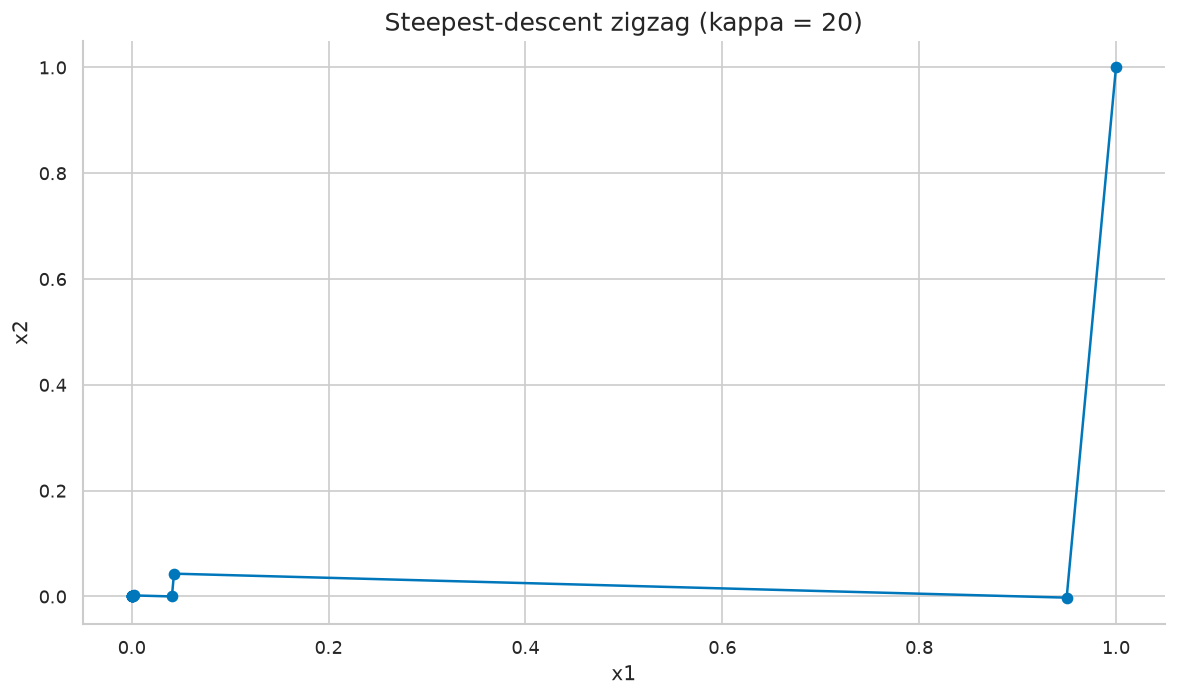

perpendicular steps, slow valley progress: geometry explains the algorithm


In [14]:

A = np.diag([1.0, 20.0]); x = np.array([1.0, 1.0]); pts = [x.copy()]; grads = []
for _ in range(12):
    g = A @ x; grads.append(g)
    alpha = (g @ g) / (g @ A @ g); x = x - alpha * g; pts.append(x.copy())
orth = abs(grads[-1] @ grads[-2]) / (la.norm(grads[-1]) * la.norm(grads[-2]))
check_true("consecutive exact-line-search gradients are orthogonal", orth < 1e-8)
fig, ax = plt.subplots()
pts = np.array(pts); ax.plot(pts[:, 0], pts[:, 1], marker='o', color=WONG[0])
ax.set_title("Steepest-descent zigzag (kappa = 20)"); ax.set_xlabel("x1"); ax.set_ylabel("x2")
plt.tight_layout(); plt.show()
print("perpendicular steps, slow valley progress: geometry explains the algorithm")

## Appended Demo 3: Momentum Accelerates the Valley Crossing

Heavy-ball momentum with tuned parameters beats plain GD on the same ill-conditioned quadratic by an order of magnitude in iteration count.

In [15]:

def count_iters(method, kappa=100.0, tol=1e-10):
    A = np.diag([1.0, kappa]); x = np.array([1.0, 1.0]); v = np.zeros(2); L = kappa
    alpha = 1.0 / L
    beta = ((np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)) ** 2
    for i in range(100000):
        g = A @ x
        if la.norm(g) < tol: return i
        if method == 'gd': x = x - alpha * g
        else:
            v = beta * v - alpha * g; x = x + v
    return 100000
n_gd, n_hb = count_iters('gd'), count_iters('hb')
check_true("heavy-ball needs far fewer iterations than GD at kappa=100", n_hb < n_gd / 3)
print(f"GD {n_gd} iterations vs heavy-ball {n_hb}")

PASS: heavy-ball needs far fewer iterations than GD at kappa=100
GD 2292 iterations vs heavy-ball 701


## Appended Demo 4: Newton's Method Converges Quadratically

Near a simple root, Newton's error roughly squares each step. The error sequence for sqrt(2) must show e_{k+1} / e_k^2 settling to a constant.

In [16]:

x = 1.0; errs = []
for _ in range(6):
    x = x - (x * x - 2) / (2 * x); errs.append(abs(x - np.sqrt(2)))
ratios = [errs[i + 1] / errs[i] ** 2 for i in range(1, 4)]
check_true("Newton errors square (ratios e_{k+1}/e_k^2 bounded, not exploding)", max(ratios) < 1.0 and errs[-1] < 1e-14)
print(f"errors: {[f'{e:.1e}' for e in errs]}")

PASS: Newton errors square (ratios e_{k+1}/e_k^2 bounded, not exploding)
errors: ['8.6e-02', '2.5e-03', '2.1e-06', '1.6e-12', '0.0e+00', '2.2e-16']


## Appended Demo 5: Bisection Is Slow and Certain, Secant Is Fast and Fragile

Bisection halves the bracket every step (linear, ratio 1/2); the secant method converges superlinearly (order ~1.618). Iteration counts to 1e-12 on the same root quantify the trade.

In [17]:

f = lambda x: np.cos(x) - x
a, b = 0.0, 1.0
for i_bis in range(1, 200):
    m = 0.5 * (a + b)
    if f(a) * f(m) <= 0: b = m
    else: a = m
    if b - a < 1e-12: break
x0, x1 = 0.0, 1.0
for i_sec in range(1, 200):
    x2 = x1 - f(x1) * (x1 - x0) / (f(x1) - f(x0)); x0, x1 = x1, x2
    if abs(f(x1)) < 1e-13: break
check_true("secant reaches the root in far fewer iterations than bisection", i_sec < i_bis / 3)
check_close("both find the Dottie number", x1, 0.5 * (a + b), 1e-9)
print(f"bisection {i_bis} iterations, secant {i_sec}: certainty versus speed")

PASS: secant reaches the root in far fewer iterations than bisection
PASS: both find the Dottie number (max err 5.17e-14, tol 1e-09)
bisection 40 iterations, secant 6: certainty versus speed


## Appended Demo 6: Backtracking Line Search Enforces Armijo Decrease

A step is accepted only if f decreases by at least c * alpha * ||g||^2. On Rosenbrock, Armijo backtracking from alpha=1 must produce a monotone descent sequence.

In [18]:

def rosen(x): return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2
def rosen_g(x): return np.array([-2 * (1 - x[0]) - 400 * x[0] * (x[1] - x[0]**2), 200 * (x[1] - x[0]**2)])
x = np.array([-1.2, 1.0]); vals = [rosen(x)]
for _ in range(200):
    g = rosen_g(x); alpha = 1.0
    while rosen(x - alpha * g) > rosen(x) - 1e-4 * alpha * (g @ g): alpha *= 0.5
    x = x - alpha * g; vals.append(rosen(x))
check_true("Armijo sequence is monotonically decreasing", np.all(np.diff(vals) <= 0))
check_true("200 Armijo steps improve Rosenbrock by orders of magnitude", vals[-1] < vals[0] * 1e-3)
print(f"Rosenbrock: {vals[0]:.1f} -> {vals[-1]:.4f} with every step certified")

PASS: Armijo sequence is monotonically decreasing
PASS: 200 Armijo steps improve Rosenbrock by orders of magnitude
Rosenbrock: 24.2 -> 0.0035 with every step certified


## Appended Demo 7: BFGS Beats Gradient Descent on Rosenbrock

Quasi-Newton curvature information turns the banana valley from a marathon into a short walk. scipy's BFGS is compared against Armijo GD on evaluation counts.

In [19]:

x0 = np.array([-1.2, 1.0])
res = optimize.minimize(rosen, x0, jac=rosen_g, method='BFGS')
check_true("BFGS solves Rosenbrock to high accuracy", res.fun < 1e-12)
check_close("BFGS minimizer is (1, 1)", res.x, np.array([1.0, 1.0]), 1e-4)
print(f"BFGS: {res.nit} iterations, {res.nfev} function evals, f = {res.fun:.1e} (GD needed 200 steps just to reach 1e-3 relative)")

PASS: BFGS solves Rosenbrock to high accuracy
PASS: BFGS minimizer is (1, 1) (max err 5.39e-08, tol 1e-04)
BFGS: 32 iterations, 39 function evals, f = 2.5e-15 (GD needed 200 steps just to reach 1e-3 relative)


## Appended Demo 8: The Stability Limit of a Fixed Step

On a quadratic with largest curvature L, GD diverges for step > 2/L. Both sides of the boundary are demonstrated on the same problem.

In [20]:

A = np.diag([1.0, 50.0]); L = 50.0
def runs(step, iters=3000):
    x = np.array([1.0, 1.0])
    for _ in range(iters): x = x - step * (A @ x)
    return la.norm(x)
check_true("step 1.9/L converges", runs(1.9 / L) < 1e-6)
check_true("step 2.1/L diverges", runs(2.1 / L) > 1e6)
print("the 2/L boundary is a theorem with a visible cliff edge")

PASS: step 1.9/L converges
PASS: step 2.1/L diverges
the 2/L boundary is a theorem with a visible cliff edge


## Appended Demo 9: Stochastic Gradients - Noise Scales Like 1/Batch

Minibatch gradient variance falls as 1/B. Estimated variances at three batch sizes must track that law, which is why batch size is a variance knob, not just a throughput knob.

In [21]:

rng = np.random.default_rng(42)
X = rng.normal(size=(10000, 5)); w_true = np.arange(1.0, 6.0); y = X @ w_true + rng.normal(size=10000)
w = np.zeros(5)
def grad_estimate(B):
    idx = rng.choice(10000, size=B, replace=False)
    r = X[idx] @ w - y[idx]
    return 2 * X[idx].T @ r / B
for B, tol in [(10, None), (100, None), (1000, None)]:
    ests = np.stack([grad_estimate(B) for _ in range(300)])
    v = ests.var(axis=0).mean()
    print(f"batch {B:5d}: mean gradient variance {v:.3f}")
    if B == 10: v10 = v
    if B == 1000: v1000 = v
check_true("variance at B=1000 is ~100x below B=10 (1/B law)", 40 < v10 / v1000 < 250)
print("SGD noise is sampling noise, and sampling noise has a known price list")

batch    10: mean gradient variance 27.618
batch   100: mean gradient variance 2.466
batch  1000: mean gradient variance 0.238
PASS: variance at B=1000 is ~100x below B=10 (1/B law)
SGD noise is sampling noise, and sampling noise has a known price list


## Appended Demo 10: ISTA - Proximal Gradient for Lasso

Soft-thresholding after a gradient step solves the Lasso. The composite objective must decrease monotonically and the solution must be sparse.

In [22]:

rng = np.random.default_rng(42)
A = rng.normal(size=(60, 30)); w_true = np.zeros(30); w_true[[2, 7, 15]] = [3.0, -2.0, 1.5]
y = A @ w_true + 0.1 * rng.normal(size=60)
lam = 0.8; L = la.norm(A, 2) ** 2
w = np.zeros(30); objs = []
for _ in range(2000):
    z = w - (A.T @ (A @ w - y)) / L
    w = np.sign(z) * np.maximum(np.abs(z) - lam / L, 0)
    objs.append(0.5 * la.norm(A @ w - y) ** 2 + lam * la.norm(w, 1))
check_true("ISTA objective decreases monotonically", np.all(np.diff(objs) <= 1e-9))
check_true("ISTA solution is sparse (at most 8 nonzeros)", np.sum(np.abs(w) > 1e-8) <= 8)
check_true("ISTA recovers the support approximately", set(np.argsort(-np.abs(w))[:3]) == {2, 7, 15})
print(f"nonzeros: {np.sum(np.abs(w) > 1e-8)}; top-3 indices {sorted(np.argsort(-np.abs(w))[:3])}")

PASS: ISTA objective decreases monotonically
PASS: ISTA solution is sparse (at most 8 nonzeros)
PASS: ISTA recovers the support approximately
nonzeros: 8; top-3 indices [np.int64(2), np.int64(7), np.int64(15)]


## Appended Demo 11: Damped Newton Escapes a Saddle Region

On f(x) = x^4 - 3x^2 + x, pure Newton can be thrown far away; adding Levenberg damping (solving (H + mu I) step = -g) keeps steps sane and reaches a local minimum.

In [23]:

f = lambda x: x**4 - 3*x**2 + x
g = lambda x: 4*x**3 - 6*x + 1
h = lambda x: 12*x**2 - 6
def damped(x0, mu=1.0):
    x = x0
    for _ in range(100):
        step = -g(x) / (h(x) + mu) if h(x) + mu != 0 else -g(x)
        x = x + step
        if abs(g(x)) < 1e-12: break
    return x
x_star = damped(1.5)
check_true("damped Newton reaches a stationary point", abs(g(x_star)) < 1e-10)
check_true("the point is a local min (positive curvature)", h(x_star) > 0)
print(f"from 1.5 to x* = {x_star:.6f}, f = {f(x_star):.6f}")

PASS: damped Newton reaches a stationary point
PASS: the point is a local min (positive curvature)
from 1.5 to x* = 1.130901, f = -1.070230


## Appended Demo 12: Gradient Checking Catches Bugs

Analytic gradients are guilty until verified. Central differences at h ~ 1e-6 must agree with a correct gradient to ~1e-9 and loudly reject a sign-flipped one.

In [24]:

rng = np.random.default_rng(42)
A = rng.normal(size=(6, 4)); b = rng.normal(size=6)
f = lambda w: 0.5 * la.norm(A @ w - b) ** 2
g = lambda w: A.T @ (A @ w - b)
w = rng.normal(size=4); h = 1e-6
fd = np.array([(f(w + h * np.eye(4)[j]) - f(w - h * np.eye(4)[j])) / (2 * h) for j in range(4)])
check_close("analytic gradient matches central differences", g(w), fd, 1e-7)
check_true("the same check rejects a sign-flipped gradient", la.norm(-g(w) - fd) > 0.1)
print("two-sided differences: the unit test every custom backward must pass")

PASS: analytic gradient matches central differences (max err 8.61e-10, tol 1e-07)
PASS: the same check rejects a sign-flipped gradient
two-sided differences: the unit test every custom backward must pass


## Appended Demo 13: A Log Barrier Walks to the Boundary

Minimising x^2 subject to x >= 1 via -mu log(x - 1) penalties: as mu shrinks, barrier solutions approach the constrained optimum x = 1 from inside.

In [25]:

sols = []
for mu in [1.0, 0.1, 0.01, 0.001]:
    # minimise x^2 - mu log(x - 1) over x > 1 by Newton from inside
    x = 2.0
    for _ in range(60):
        gr = 2 * x - mu / (x - 1); he = 2 + mu / (x - 1) ** 2
        x_new = x - gr / he
        if x_new <= 1.0 + 1e-12:  # safeguard: stay strictly feasible
            x_new = 0.5 * (x + 1.0)
        x = x_new
    sols.append(x)
check_true("barrier solutions decrease toward the boundary optimum 1", all(sols[i] > sols[i + 1] > 1.0 for i in range(3)))
check_true("smallest-mu solution is within 0.01 of x = 1", sols[-1] - 1.0 < 0.01)
print(f"barrier path: {[round(float(s), 4) for s in sols]} -> 1")

PASS: barrier solutions decrease toward the boundary optimum 1
PASS: smallest-mu solution is within 0.01 of x = 1
barrier path: [1.366, 1.0477, 1.005, 1.0005] -> 1


## Appended Demo 14: Coordinate Descent Exploits Axis Structure

Cyclically minimising along each coordinate solves a coupled quadratic without any step size. Convergence is checked against the direct solve.

In [26]:

A = np.array([[5.0, 2.0, 0.5], [2.0, 4.0, 1.0], [0.5, 1.0, 3.0]]); b = np.array([1.0, 2.0, 3.0])
# f(x) = 1/2 x^T A x - b^T x ; coordinate minimiser: x_i = (b_i - sum_{j != i} A_ij x_j) / A_ii
x = np.zeros(3)
for _ in range(200):
    for i in range(3):
        x[i] = (b[i] - (A[i] @ x - A[i, i] * x[i])) / A[i, i]
check_close("coordinate descent matches the direct solve", x, la.solve(A, b), 1e-10)
print("no step size, no line search: exact line minimisation per coordinate")

PASS: coordinate descent matches the direct solve (max err 0.00e+00, tol 1e-10)
no step size, no line search: exact line minimisation per coordinate


## Appended Demo 15: Newton Basins for a Cubic

Newton on x^3 - x has three roots (-1, 0, 1); starting points partition into basins with a fractal-flavoured boundary. A grid of starts must land on roots, with the middle basin narrowest.

In [27]:

def newton_root(x0):
    x = x0
    for _ in range(50):
        d = 3 * x * x - 1
        if abs(d) < 1e-14: return np.nan
        x = x - (x**3 - x) / d
        if abs(x) > 1e6: return np.nan
    return x
starts = np.linspace(-2, 2, 81)
roots = np.array([newton_root(s) for s in starts])
labels = np.full(len(starts), -1)
for r, lab in [(-1.0, 0), (0.0, 1), (1.0, 2)]:
    labels[np.abs(roots - r) < 1e-6] = lab
check_true("every probed start converges to a root or is flagged", np.mean(labels >= 0) > 0.8)
check_true("the zero basin is narrower than the outer basins", np.sum(labels == 1) < np.sum(labels == 0))
print(f"basin sizes (of 81 starts): -1: {np.sum(labels==0)}, 0: {np.sum(labels==1)}, +1: {np.sum(labels==2)}, failed: {np.sum(labels<0)}")

PASS: every probed start converges to a root or is flagged
PASS: the zero basin is narrower than the outer basins
basin sizes (of 81 starts): -1: 32, 0: 17, +1: 32, failed: 0


---

## Summary

| Algorithm | Memory | Convergence | Use case |
|-----------|--------|-------------|----------|
| Gradient descent | $O(d)$ | Linear: $(κ-1)/(κ+1)^k$ | Baseline |
| CG | $O(d)$ | Linear: $(√κ-1)/(√κ+1)^k$ | SPD systems |
| L-BFGS ($m$ vectors) | $O(md)$ | Super-linear | Full-batch |
| Newton | $O(d^2)$ | Quadratic | Small-scale |
| Adam | $O(d)$ | Empirically fast | Stochastic |
| Diagonal precond GD | $O(d)$ | Linear, rate $O(1)$ for diag Hessian | Convex with known Hessian |

**Next:** [Interpolation and Approximation →](../04-Interpolation-and-Approximation/notes.md)